In [2]:
print("Hello")

Hello


# Importing Libraries

In [74]:
import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
import shap
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score, precision_recall_curve, auc
from collections import Counter
import plotly.express as px
from plotly.subplots import make_subplots
import plotly.graph_objects as go
import joblib


# 1.Importing Data and Understanding

In [4]:
df=pd.read_csv('creditcard.csv')

In [5]:
df.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [6]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:\n", df.columns.tolist())

Dataset Shape: (284807, 31)

Column Names:
 ['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 284807 entries, 0 to 284806
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    284807 non-null  float64
 1   V1      284807 non-null  float64
 2   V2      284807 non-null  float64
 3   V3      284807 non-null  float64
 4   V4      284807 non-null  float64
 5   V5      284807 non-null  float64
 6   V6      284807 non-null  float64
 7   V7      284807 non-null  float64
 8   V8      284807 non-null  float64
 9   V9      284807 non-null  float64
 10  V10     284807 non-null  float64
 11  V11     284807 non-null  float64
 12  V12     284807 non-null  float64
 13  V13     284807 non-null  float64
 14  V14     284807 non-null  float64
 15  V15     284807 non-null  float64
 16  V16     284807 non-null  float64
 17  V17     284807 non-null  float64
 18  V18     284807 non-null  float64
 19  V19     284807 non-null  float64
 20  V20     284807 non-null  float64
 21  V21     28

In [8]:

print("Missing Values:\n", df.isnull().sum())

Missing Values:
 Time      0
V1        0
V2        0
V3        0
V4        0
V5        0
V6        0
V7        0
V8        0
V9        0
V10       0
V11       0
V12       0
V13       0
V14       0
V15       0
V16       0
V17       0
V18       0
V19       0
V20       0
V21       0
V22       0
V23       0
V24       0
V25       0
V26       0
V27       0
V28       0
Amount    0
Class     0
dtype: int64


In [9]:
class_counts = df['Class'].value_counts()
class_ratio = df['Class'].value_counts(normalize=True)

print("Class Counts:\n", class_counts)
print("\nClass Ratio:\n", class_ratio)

Class Counts:
 Class
0    284315
1       492
Name: count, dtype: int64

Class Ratio:
 Class
0    0.998273
1    0.001727
Name: proportion, dtype: float64


In [10]:
# Percentage of fraud cases
fraud_percentage = class_ratio[1] * 100
print(f"Fraud Transactions: {fraud_percentage:.4f}%")

Fraud Transactions: 0.1727%


In [11]:
df[['Time', 'Amount']].describe()

,Time,Amount
count,284807.000000,284807.000000
mean,94813.859575,88.349619
std,47488.145955,250.120109
min,0.000000,0.000000
25%,54201.500000,5.600000
50%,84692.000000,22.000000
75%,139320.500000,77.165000
max,172792.000000,25691.160000


In [12]:
df['Amount'].skew()

np.float64(16.977724453761006)

In [13]:
pca_features = [col for col in df.columns if col.startswith('V')]
numerical_features = ['Time', 'Amount']
target = 'Class'

print(f"PCA Features: {len(pca_features)}")
print("Numerical Features:", numerical_features)
print("Target:", target)

PCA Features: 28
Numerical Features: ['Time', 'Amount']
Target: Class


In [14]:
duplicates = df.duplicated().sum()
print("Duplicate Rows:", duplicates)

Duplicate Rows: 1081


In [15]:
df['Class'].unique()

array([0, 1])

# 2. Exploratory Data Analysis

In [16]:
sns.set(style="whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)

In [17]:
class_counts = df['Class'].value_counts().reset_index()
class_counts.columns = ['Transaction Type', 'Count']
class_counts['Transaction Type'] = class_counts['Transaction Type'].map({0: 'Legitimate', 1: 'Fraud'})


fig = px.bar(
    class_counts,
    x='Transaction Type',
    y='Count',
    text_auto='.2s',
    title="Class Distribution (Severely Imbalanced)",
    color='Transaction Type',
    color_discrete_map={'Legitimate': '#636EFA', 'Fraud': '#EF553B'}
)


fig.update_traces(textposition='outside')
fig.show()

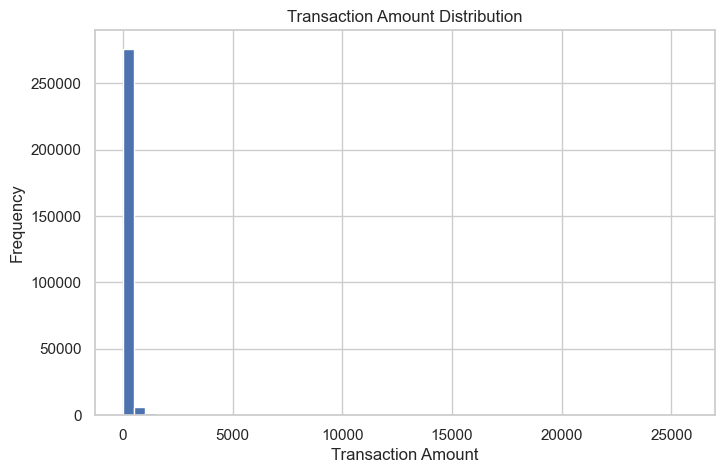

In [18]:
# Amount distribution (full data)
plt.hist(df['Amount'], bins=50)
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.title("Transaction Amount Distribution")
plt.show()

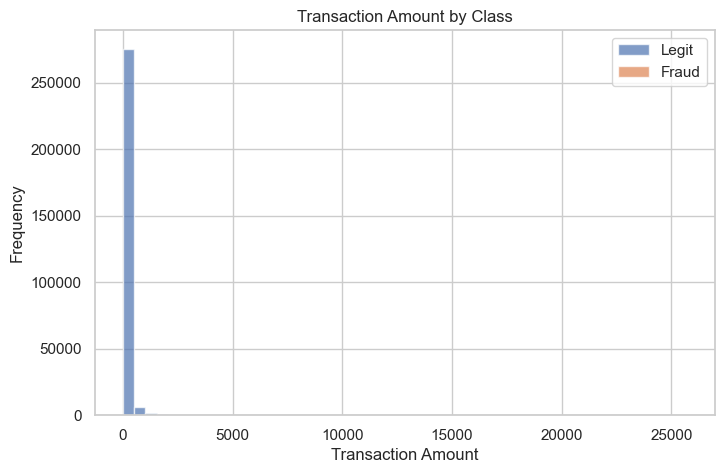

In [19]:
# Amount comparison: Fraud vs Legit
plt.hist(df[df['Class'] == 0]['Amount'], bins=50, alpha=0.7, label='Legit')
plt.hist(df[df['Class'] == 1]['Amount'], bins=50, alpha=0.7, label='Fraud')
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")
plt.legend()
plt.title("Transaction Amount by Class")
plt.show()

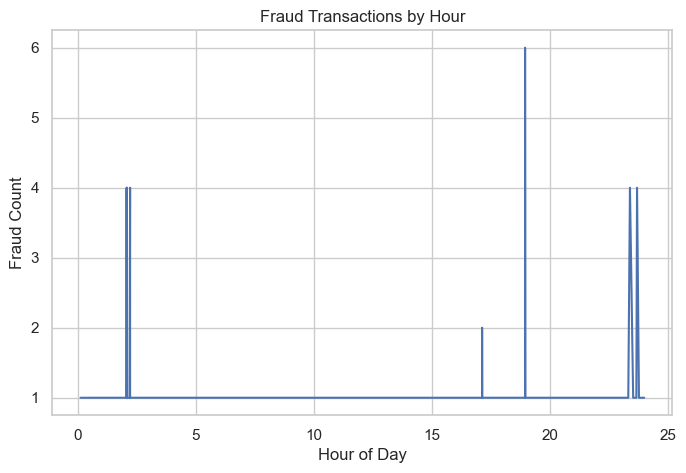

In [20]:
# Convert Time to hours
df['Hour'] = (df['Time'] / 3600) % 24

# Fraud count by hour
fraud_by_hour = df[df['Class'] == 1]['Hour'].value_counts().sort_index()

plt.plot(fraud_by_hour.index, fraud_by_hour.values)
plt.xlabel("Hour of Day")
plt.ylabel("Fraud Count")
plt.title("Fraud Transactions by Hour")
plt.show()

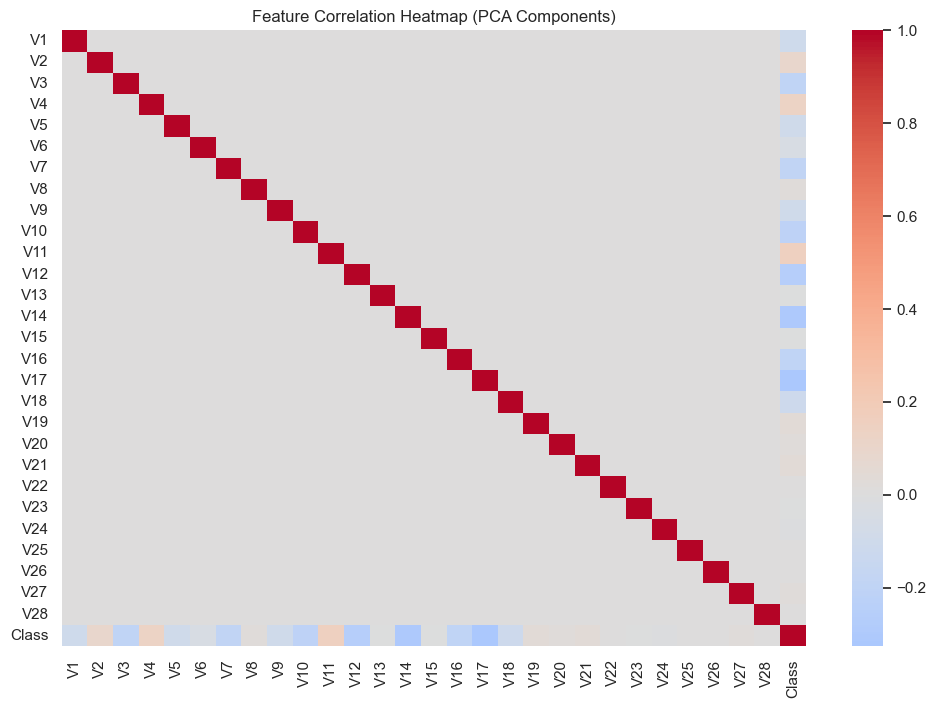

In [21]:
# Correlation matrix (subset for performance)
corr = df[pca_features + ['Class']].corr()

plt.figure(figsize=(12, 8))
sns.heatmap(corr, cmap="coolwarm", center=0)
plt.title("Feature Correlation Heatmap (PCA Components)")
plt.show()

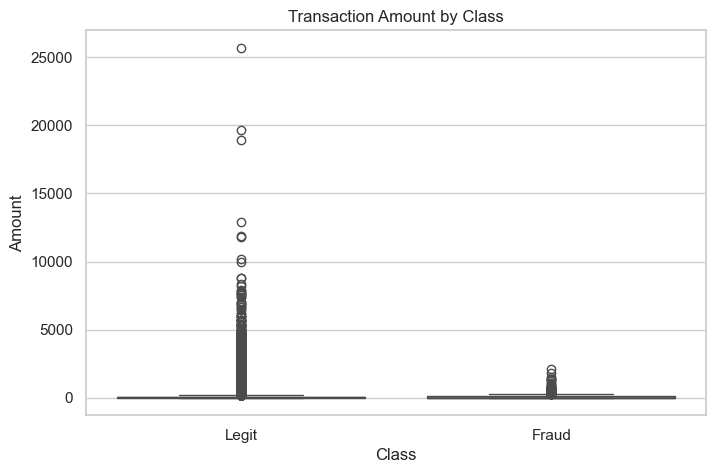

In [22]:
# Boxplot for Amount
sns.boxplot(x='Class', y='Amount', data=df)
plt.xticks([0, 1], ['Legit', 'Fraud'])
plt.title("Transaction Amount by Class")
plt.show()

In [23]:
# Descriptive stats by class
df.groupby('Class')['Amount'].describe()

,count,mean,std,min,25%,50%,75%,max
Class,,,,,,,,
0,284315.0,88.291022,250.105092,0.0,5.65,22.00,77.05,25691.16
1,492.0,122.211321,256.683288,0.0,1.00,9.25,105.89,2125.87


# Feature Engineering

In [24]:
df['log_amount'] = np.log1p(df['Amount'])


In [25]:
df['Hour'] = (df['Time'] / 3600) % 24

In [26]:
# Sort by time
df = df.sort_values('Time')

# Time difference between transactions
df['time_diff'] = df['Time'].diff().fillna(0)

In [27]:
# Rolling mean of amount
df['rolling_amount_mean'] = (
    df['Amount']
    .rolling(window=10, min_periods=1)
    .mean()
)

# Rolling standard deviation
df['rolling_amount_std'] = (
    df['Amount']
    .rolling(window=10, min_periods=1)
    .std()
    .fillna(0)
)

In [28]:
# Interaction between amount and time difference
df['amount_time_interaction'] = df['Amount'] * df['time_diff']


In [29]:
# Aggregate PCA features
df['pca_sum'] = df[pca_features].sum(axis=1)
df['pca_mean'] = df[pca_features].mean(axis=1)
df['pca_std'] = df[pca_features].std(axis=1)


In [30]:
# Correlation with target
feature_corr = df.corr()['Class'].sort_values(ascending=False)

# Top features correlated with fraud
feature_corr.head(15)


Class                      1.000000
pca_std                    0.250839
V11                        0.154876
V4                         0.133447
V2                         0.091289
V21                        0.040413
V19                        0.034783
V20                        0.020090
V8                         0.019875
time_diff                  0.018983
V27                        0.017580
amount_time_interaction    0.010386
V28                        0.009536
Amount                     0.005632
V26                        0.004455
Name: Class, dtype: float64

In [31]:
# Final feature list (example)
engineered_features = [
    'log_amount',
    'Hour',
    'time_diff',
    'rolling_amount_mean',
    'rolling_amount_std',
    'amount_time_interaction',
    'pca_sum',
    'pca_mean',
    'pca_std'
]

X = df[pca_features + engineered_features]
y = df['Class']


In [ ]:
FEATURE_COLUMNS = X_train.columns.tolist()

print("Number of features:", len(FEATURE_COLUMNS))
FEATURE_COLUMNS

Number of features: 37


['V1',
 'V2',
 'V3',
 'V4',
 'V5',
 'V6',
 'V7',
 'V8',
 'V9',
 'V10',
 'V11',
 'V12',
 'V13',
 'V14',
 'V15',
 'V16',
 'V17',
 'V18',
 'V19',
 'V20',
 'V21',
 'V22',
 'V23',
 'V24',
 'V25',
 'V26',
 'V27',
 'V28',
 'log_amount',
 'Hour',
 'time_diff',
 'rolling_amount_mean',
 'rolling_amount_std',
 'amount_time_interaction',
 'pca_sum',
 'pca_mean',
 'pca_std']

In [32]:
# Check for NaNs after feature engineering
X.isnull().sum().sum()


np.int64(0)

In [33]:
# Train-test split with stratification
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    stratify=y,
    random_state=42
)

print("Train shape:", X_train.shape)
print("Test shape:", X_test.shape)


Train shape: (227845, 37)
Test shape: (56962, 37)


In [34]:
# Numerical features requiring scaling
scale_features = [
    'Amount',
    'log_amount',
    'time_diff',
    'rolling_amount_mean',
    'rolling_amount_std',
    'amount_time_interaction'
]

# Ensure features exist
scale_features = [f for f in scale_features if f in X_train.columns]


In [35]:
# RobustScaler is resistant to outliers
scaler = RobustScaler()

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

# Fit only on training data (NO LEAKAGE)
X_train_scaled[scale_features] = scaler.fit_transform(
    X_train[scale_features]
)

# Transform test data
X_test_scaled[scale_features] = scaler.transform(
    X_test[scale_features]
)


In [36]:
# Check for NaNs or infinities
assert not np.isnan(X_train_scaled.values).any()
assert not np.isnan(X_test_scaled.values).any()

assert np.isfinite(X_train_scaled.values).all()
assert np.isfinite(X_test_scaled.values).all()


In [37]:
# Final modeling datasets
X_train_final = X_train_scaled
X_test_final = X_test_scaled

y_train_final = y_train
y_test_final = y_test


In [38]:
# Class distribution before SMOTE
print("Before SMOTE:")
print(Counter(y_train_final))

Before SMOTE:
Counter({0: 227451, 1: 394})


In [39]:
# Initialize SMOTE
smote = SMOTE(
    sampling_strategy='auto',
    random_state=42,
    k_neighbors=5
)

# Apply SMOTE only on training data
X_train_smote, y_train_smote = smote.fit_resample(
    X_train_final,
    y_train_final
)


In [40]:
# Class distribution after SMOTE
print("After SMOTE:")
print(Counter(y_train_smote))


After SMOTE:
Counter({0: 227451, 1: 227451})


In [41]:
print("Original Training Shape:", X_train_final.shape)
print("SMOTE Training Shape:", X_train_smote.shape)


Original Training Shape: (227845, 37)
SMOTE Training Shape: (454902, 37)


In [42]:
# Choose one strategy for modeling
X_train_model = X_train_smote
y_train_model = y_train_smote

X_test_model = X_test_final
y_test_model = y_test_final


In [43]:
# Initialize Logistic Regression
log_reg = LogisticRegression(
    max_iter=1000,
    solver='lbfgs',
    n_jobs=-1
)

# Train model
log_reg.fit(X_train_model, y_train_model)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [44]:
# Predict class labels
y_pred = log_reg.predict(X_test_model)

# Predict probabilities (needed for PR-AUC)
y_pred_proba = log_reg.predict_proba(X_test_model)[:, 1]


In [45]:
cm = confusion_matrix(y_test_model, y_pred)
cm


array([[55273,  1591],
       [    8,    90]])

In [46]:
print(classification_report(y_test_model, y_pred, digits=4))


              precision    recall  f1-score   support

           0     0.9999    0.9720    0.9857     56864
           1     0.0535    0.9184    0.1012        98

    accuracy                         0.9719     56962
   macro avg     0.5267    0.9452    0.5435     56962
weighted avg     0.9982    0.9719    0.9842     56962



In [47]:
roc_auc = roc_auc_score(y_test_model, y_pred_proba)
print("ROC-AUC:", roc_auc)


ROC-AUC: 0.9762234346467906


In [48]:
precision, recall, thresholds = precision_recall_curve(
    y_test_model,
    y_pred_proba
)

pr_auc = auc(recall, precision)
print("PR-AUC:", pr_auc)


PR-AUC: 0.7808487797858232


In [49]:
rf = RandomForestClassifier(
    n_estimators=200,
    max_depth=10,
    min_samples_split=50,
    min_samples_leaf=20,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_model, y_train_model)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",200
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",50
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",20
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [50]:
y_pred_rf = rf.predict(X_test_model)
y_proba_rf = rf.predict_proba(X_test_model)[:, 1]

print("Random Forest")
print(classification_report(y_test_model, y_pred_rf, digits=4))

rf_pr_auc = auc(
    precision_recall_curve(y_test_model, y_proba_rf)[1],
    precision_recall_curve(y_test_model, y_proba_rf)[0]
)

print("PR-AUC:", rf_pr_auc)


Random Forest
              precision    recall  f1-score   support

           0     0.9998    0.9976    0.9987     56864
           1     0.3964    0.8980    0.5500        98

    accuracy                         0.9975     56962
   macro avg     0.6981    0.9478    0.7744     56962
weighted avg     0.9988    0.9975    0.9980     56962

PR-AUC: 0.8166239126971316


In [51]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=(y_train_model == 0).sum() / (y_train_model == 1).sum(),
    eval_metric='logloss',
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train_model, y_train_model)


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

In [52]:
y_pred_xgb = xgb.predict(X_test_model)
y_proba_xgb = xgb.predict_proba(X_test_model)[:, 1]

print("XGBoost")
print(classification_report(y_test_model, y_pred_xgb, digits=4))

xgb_pr_auc = auc(
    precision_recall_curve(y_test_model, y_proba_xgb)[1],
    precision_recall_curve(y_test_model, y_proba_xgb)[0]
)
print("PR-AUC:", xgb_pr_auc)


XGBoost
              precision    recall  f1-score   support

           0     0.9998    0.9991    0.9994     56864
           1     0.6277    0.8776    0.7319        98

    accuracy                         0.9989     56962
   macro avg     0.8138    0.9383    0.8657     56962
weighted avg     0.9991    0.9989    0.9990     56962

PR-AUC: 0.8699816462349075


In [53]:
from lightgbm import LGBMClassifier

lgbm = LGBMClassifier(
    n_estimators=500,
    num_leaves=31,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1
)

lgbm.fit(X_train_model, y_train_model)


[LightGBM] [Info] Number of positive: 227451, number of negative: 227451
[LightGBM] [Info] Auto-choosing col-wise multi-threading, the overhead of testing was 0.095827 seconds.
You can set `force_col_wise=true` to remove the overhead.
[LightGBM] [Info] Total Bins 9435
[LightGBM] [Info] Number of data points in the train set: 454902, number of used features: 37
[LightGBM] [Info] [binary:BoostFromScore]: pavg=0.500000 -> initscore=0.000000


,boosting_type,'gbdt'
,num_leaves,31
,max_depth,-1
,learning_rate,0.05
,n_estimators,500
,subsample_for_bin,200000
,objective,None
,class_weight,'balanced'
,min_split_gain,0.0
,min_child_weight,0.001
,min_child_samples,20


In [54]:
y_pred_lgbm = lgbm.predict(X_test_model)
y_proba_lgbm = lgbm.predict_proba(X_test_model)[:, 1]

print("LightGBM")
print(classification_report(y_test_model, y_pred_lgbm, digits=4))

lgbm_pr_auc = auc(
    precision_recall_curve(y_test_model, y_proba_lgbm)[1],
    precision_recall_curve(y_test_model, y_proba_lgbm)[0]
)
print("PR-AUC:", lgbm_pr_auc)


LightGBM
              precision    recall  f1-score   support

           0     0.9997    0.9997    0.9997     56864
           1     0.8454    0.8367    0.8410        98

    accuracy                         0.9995     56962
   macro avg     0.9225    0.9182    0.9204     56962
weighted avg     0.9995    0.9995    0.9995     56962

PR-AUC: 0.8217880359894659


In [55]:
results = pd.DataFrame({
    "Model": ["Logistic", "RandomForest", "XGBoost", "LightGBM"],
    "PR-AUC": [pr_auc, rf_pr_auc, xgb_pr_auc, lgbm_pr_auc]
})

results.sort_values("PR-AUC", ascending=False)


,Model,PR-AUC
2,XGBoost,0.869982
3,LightGBM,0.821788
1,RandomForest,0.816624
0,Logistic,0.780849


In [56]:
best_model = xgb

In [61]:
model_outputs = {
    "Logistic Regression": {
        "y_true": y_test,
        "y_pred": y_pred,
        "y_proba": y_pred_proba
    },
    "Random Forest": {
        "y_true": y_test,
        "y_pred": y_pred_rf,
        "y_proba": y_proba_rf
    },
    "XGBoost": {
        "y_true": y_test,
        "y_pred": y_pred_xgb,
        "y_proba": y_proba_xgb
    },
    "LightGBM": {
        "y_true": y_test,
        "y_pred": y_pred_lgbm,
        "y_proba": y_proba_lgbm
    }
}

np.save("results/model_outputs.npy", model_outputs, allow_pickle=True)

(2000, 37) (2000, 37)


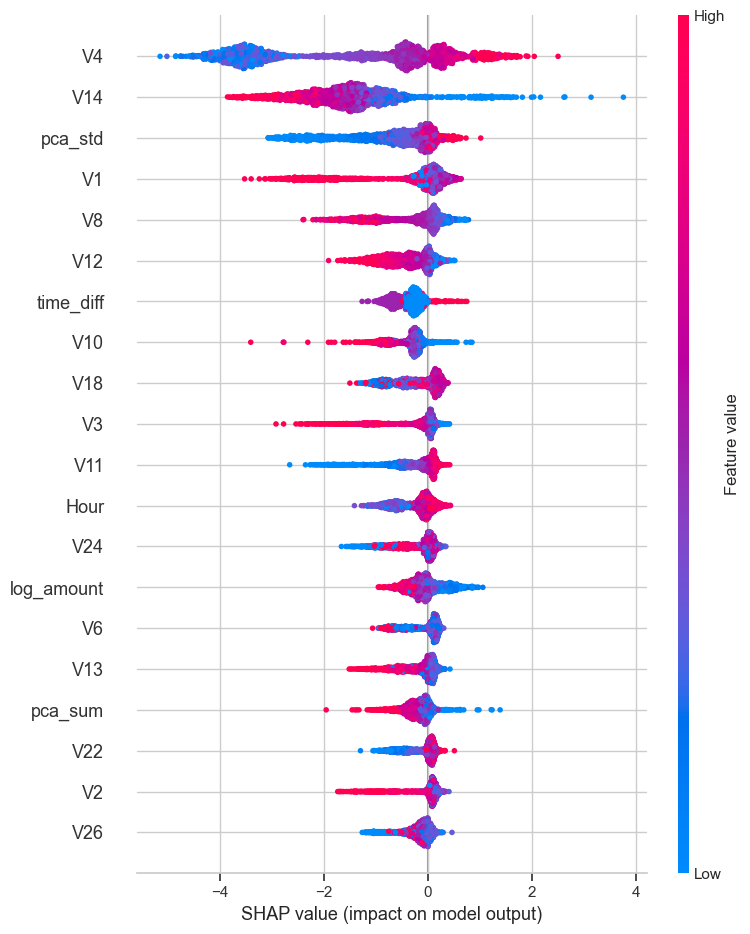

In [62]:
# Create SHAP explainer
explainer = shap.TreeExplainer(best_model)

# Sample data for SHAP
X_shap = X_test_model.sample(2000, random_state=42)

# Compute SHAP values
shap_values = explainer.shap_values(X_shap)

# Handle binary classification safely
if isinstance(shap_values, list):
    shap_values_to_plot = shap_values[1]   # fraud class
else:
    shap_values_to_plot = shap_values       # already correct shape

# Sanity check (optional but recommended)
print(shap_values_to_plot.shape, X_shap.shape)

# Summary plot
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    show=True
)


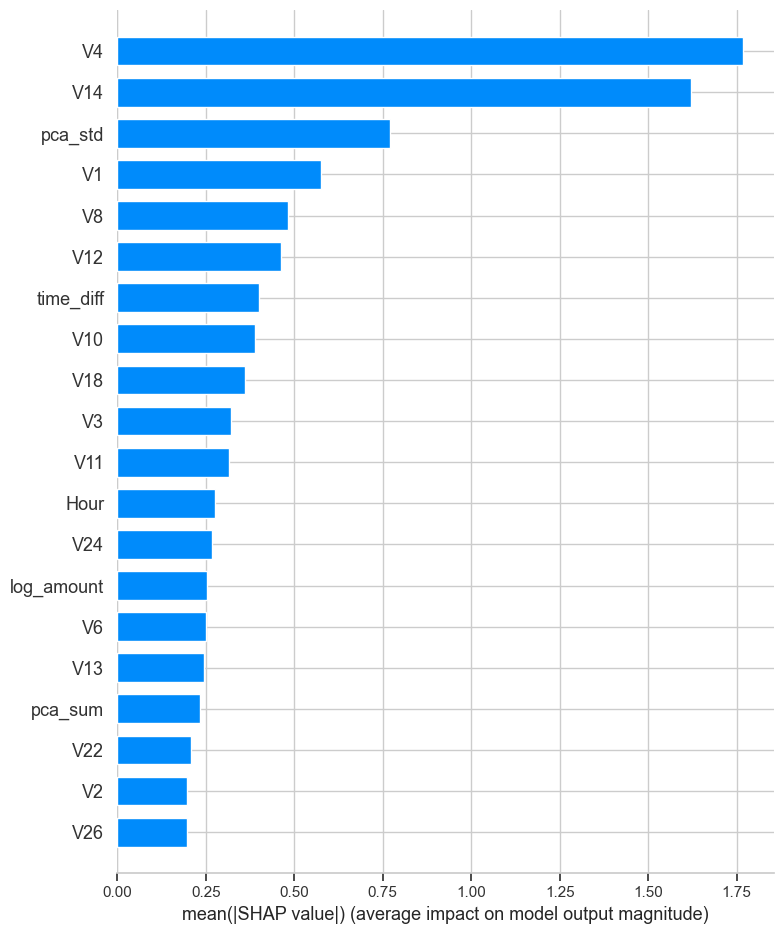

In [63]:
# Global feature importance (mean |SHAP|)
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    plot_type="bar",
    show=True
)


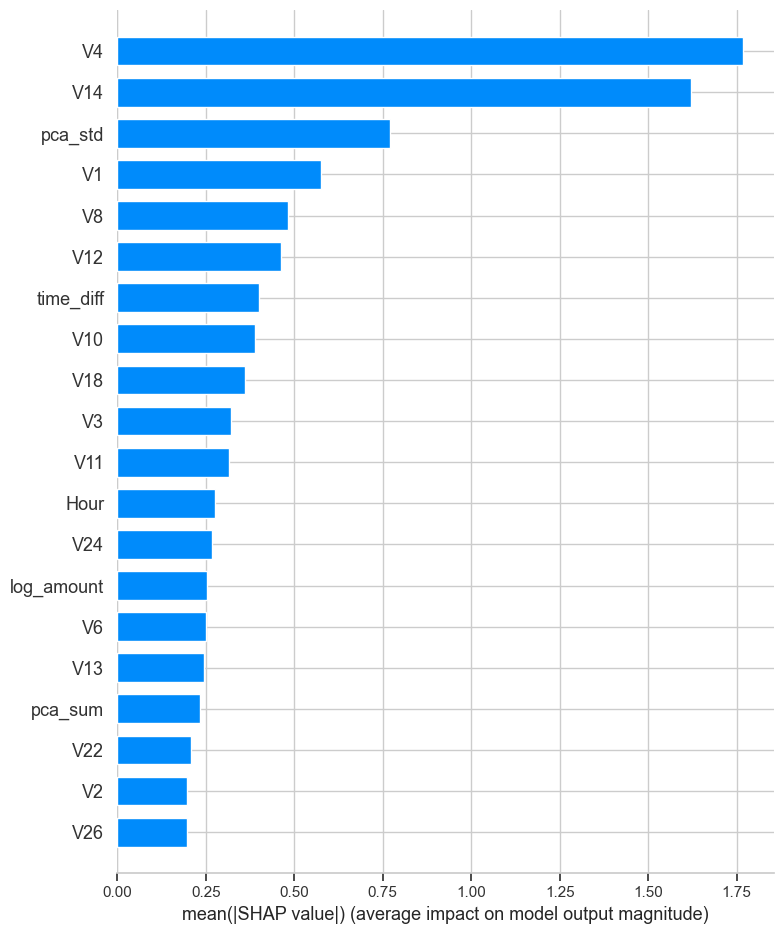

In [64]:
# Global feature importance (mean |SHAP|)
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    plot_type="bar",
    show=True
)


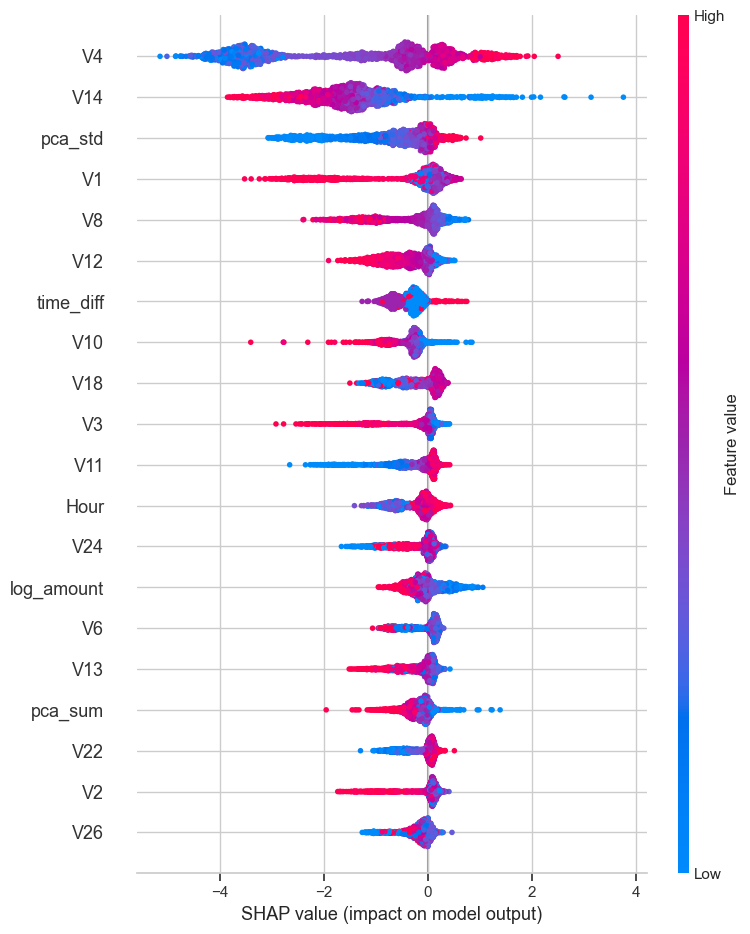

In [65]:
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    plot_type="dot",
    show=True
)


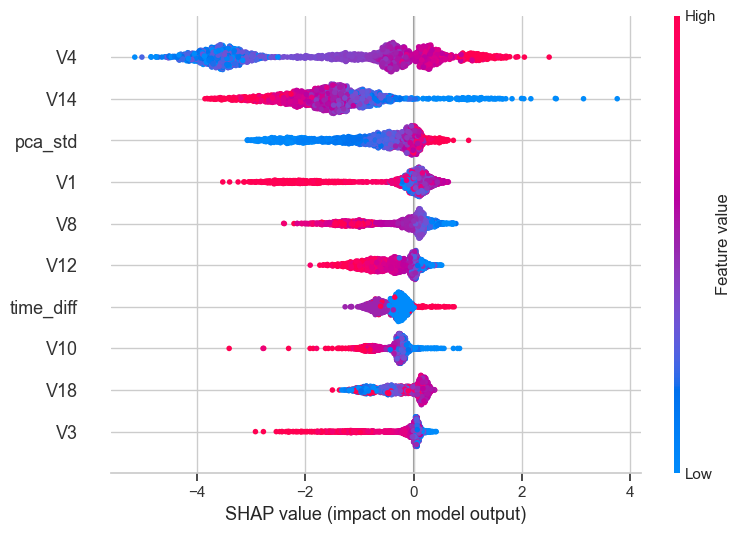

In [66]:
# Top 10 features only
shap.summary_plot(
    shap_values_to_plot,
    X_shap,
    max_display=10,
    show=True
)


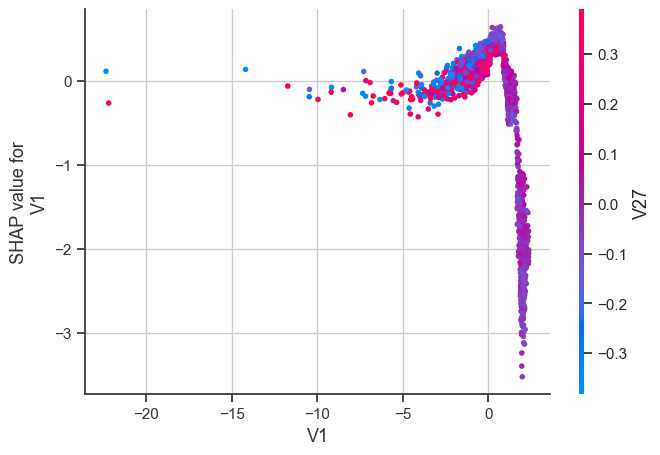

In [67]:
# Choose a strong feature from summary plot
feature_name = X_shap.columns[0]

shap.dependence_plot(
    feature_name,
    shap_values_to_plot,
    X_shap,
    interaction_index="auto",
    show=True
)


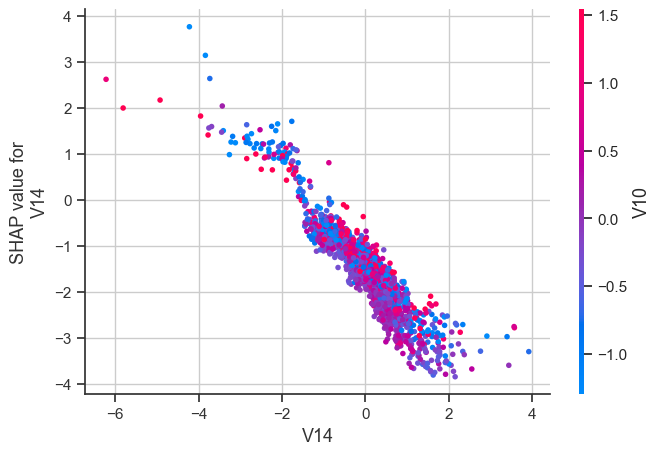

In [68]:
shap.dependence_plot(
    "V14",           # example
    shap_values_to_plot,
    X_shap,
    interaction_index="V10",
    show=True
)


In [71]:
shap_df = pd.DataFrame(
    shap_values_to_plot,
    columns=X_shap.columns
)

shap_df.abs().describe()


,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,...,V28,log_amount,Hour,time_diff,rolling_amount_mean,rolling_amount_std,amount_time_interaction,pca_sum,pca_mean,pca_std
count,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,...,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000,2000.000000
mean,0.574122,0.196836,0.321365,1.767302,0.118942,0.251430,0.098563,0.481914,0.127099,0.388976,...,0.102442,0.253945,0.275815,0.398907,0.066762,0.045999,0.179215,0.233533,0.054639,0.770422
std,0.817570,0.281156,0.497362,1.496406,0.129327,0.219731,0.097693,0.508353,0.162739,0.303716,...,0.133278,0.195934,0.281274,0.235262,0.107080,0.053476,0.120658,0.218050,0.035789,0.795641
min,0.000232,0.000261,0.000029,0.004054,0.000069,0.000274,0.000125,0.000078,0.000024,0.000195,...,0.000019,0.000103,0.000026,0.003766,0.000015,0.000004,0.000291,0.000824,0.000137,0.000236
25%,0.088307,0.069776,0.047667,0.392392,0.040123,0.112526,0.040554,0.104763,0.030536,0.199121,...,0.033561,0.091069,0.062651,0.215845,0.008328,0.016064,0.091155,0.066683,0.030989,0.133462
50%,0.192802,0.108616,0.089529,1.157805,0.078611,0.163524,0.073510,0.225920,0.061435,0.273507,...,0.063821,0.210750,0.144984,0.331892,0.018464,0.031760,0.181022,0.173300,0.048253,0.472033
75%,0.429629,0.167782,0.245749,3.399993,0.139583,0.307101,0.130518,0.879282,0.135057,0.523881,...,0.117306,0.388542,0.491136,0.601093,0.052448,0.051765,0.241748,0.333028,0.069087,1.164520
max,3.522854,1.731967,2.919211,5.147636,0.989504,1.062121,1.429062,2.398435,1.028747,3.404444,...,1.171964,1.058162,1.411161,1.263845,0.530589,0.356011,1.008193,1.953705,0.337114,3.069784


In [75]:
joblib.dump(best_model, "results/best_model.joblib")

['results/best_model.joblib']